# 2.0 – Tiền xử lý, huấn luyện và đánh giá

In [1]:
import sys, warnings
sys.path.append('../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image
import data_processing as dp
from data_processing import *
sns.set_theme(style='whitegrid')
FIG = FIGURES_DIR
def save(name): plt.tight_layout(); plt.savefig(FIG / name, dpi=130)
import joblib, json
import train as T

## Tiền xử lý và chia dữ liệu

In [2]:
train, val, test, info = prepare_datasets()
print('Outlier loại khỏi train:', info['n_removed'], '/', info['n_before'], '| ngưỡng:', info['thresholds'])
print({k: len(v) for k, v in dict(train=train, val=val, test=test).items()})
print('id chung train-test:', len(set(train['id']) & set(test['id'])),
      '| train-val:', len(set(train['id']) & set(val['id'])), '| val-test:', len(set(val['id']) & set(test['id'])))
display(train[FEATURE_COLS].head())

Outlier loại khỏi train: 11 / 15130 | ngưỡng: {'sqft_living': 8150.0, 'sqft_above': 7200.0, 'sqft_basement': 3420.0}
{'train': 15119, 'val': 3242, 'test': 3241}
id chung train-test: 0 | train-val: 0 | val-test: 0


,bedrooms,bathrooms,sqft_living,sqft_lot,floors,view,condition,grade,sqft_above,sqft_basement,...,long,sqft_living15,sqft_lot15,house_age,sale_year,sale_month,waterfront,was_renovated,has_basement,zipcode
0,3,1.0,1180,5650,1.0,0,3,7,1180.0,0,...,-122.257,1340,5650,59,2014,10,0,0,0,98178
2,2,1.0,770,10000,1.0,0,3,6,770.0,0,...,-122.233,2720,8062,82,2015,2,0,0,0,98028
7,3,1.5,1060,9711,1.0,0,3,7,1060.0,0,...,-122.315,1650,9711,52,2015,1,0,0,0,98198
8,3,1.0,1780,7470,1.0,0,3,7,1050.0,730,...,-122.337,1780,8113,55,2015,4,0,0,1,98146
9,3,2.5,1890,6560,2.0,0,3,7,1890.0,0,...,-122.031,2390,7570,12,2015,3,0,0,0,98038


## Huấn luyện (K-Means, GridSearchCV + GroupKFold, 8 mô hình)

In [3]:
T.main()

{'train': 15119, 'val': 3242, 'test': 3241, 'total': 21613, 'n_before': 15130, 'n_removed': 11, 'thresholds': {'sqft_living': 8150.0, 'sqft_above': 7200.0, 'sqft_basement': 3420.0}}


K-Means k = 8


Linear Regression  CV(log) 0.1806 | train R2=0.8665 val R2=0.8461 test R2=0.8784 MAE=76,383  {}  [1s]


Ridge              CV(log) 0.1806 | train R2=0.8665 val R2=0.8462 test R2=0.8786 MAE=76,378  {'model__alpha': 0.1}  [2s]


Lasso              CV(log) 0.1813 | train R2=0.8663 val R2=0.8467 test R2=0.8817 MAE=76,593  {'model__alpha': 0.0001}  [166s]


...

Random Forest      CV(log) 0.1744 | train R2=0.9780 val R2=0.8605 test R2=0.8755 MAE=72,116  {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}  [41s]


XGBoost            CV(log) 0.1592 | train R2=0.9524 val R2=0.9071 test R2=0.8903 MAE=64,478  {'model__learning_rate': 0.06, 'model__max_depth': 4, 'model__n_estimators': 800}  [27s]


KNN                CV(log) 0.2106 | train R2=1.0000 val R2=0.7566 test R2=0.7789 MAE=91,951  {'model__n_neighbors': 10, 'model__weights': 'distance'}  [5s]


MLP                CV(log) 0.1967 | train R2=0.8780 val R2=0.7640 test R2=0.8262 MAE=84,835  {'model__alpha': 0.01, 'model__hidden_layer_sizes': (64, 32)}  [107s]


Best model (by validation RMSE): XGBoost


## Kết quả

In [4]:
res = pd.read_csv(ROOT / 'reports' / 'results.csv')
cols = ['Model', 'Train_MAE', 'Train_R2', 'Val_R2', 'Test_MAE', 'Test_MSE', 'Test_RMSE', 'Test_R2', 'CV_RMSE_log', 'CV_std']
display(res[cols].round(4).style.format({'Train_MAE': '{:,.0f}', 'Test_MAE': '{:,.0f}', 'Test_MSE': '{:,.3e}', 'Test_RMSE': '{:,.0f}'}))
print(res[['Model', 'Best_params']].to_string(index=False))

,Model,Train_MAE,Train_R2,Val_R2,Test_MAE,Test_MSE,Test_RMSE,Test_R2,CV_RMSE_log,CV_std
0,Linear Regression,"72,986",0.866500,0.846100,"76,383",1.899e+10,"137,822",0.878400,0.180600,0.003200
1,Ridge,"72,988",0.866500,0.846200,"76,378",1.897e+10,"137,719",0.878600,0.180600,0.003200
2,Lasso,"73,432",0.866300,0.846700,"76,593",1.847e+10,"135,907",0.881700,0.181300,0.002900
3,Decision Tree,"71,693",0.853100,0.779200,"92,803",3.290e+10,"181,386",0.789300,0.213900,0.005700
4,Random Forest,"25,850",0.978000,0.860500,"72,116",1.944e+10,"139,435",0.875500,0.174400,0.005100
5,XGBoost,"48,157",0.952400,0.907100,"64,478",1.713e+10,"130,863",0.890300,0.159200,0.003000
6,KNN,0,1.000000,0.756600,"91,951",3.454e+10,"185,837",0.778900,0.210600,0.004100
7,MLP,"70,278",0.878000,0.764000,"84,835",2.715e+10,"164,763",0.826200,0.196700,0.002900


            Model                                                     Best_params
Linear Regression                                                              {}
            Ridge                                                  {"alpha": 0.1}
            Lasso                                               {"alpha": 0.0001}
    Decision Tree                       {"max_depth": 16, "min_samples_leaf": 20}
    Random Forest {"max_depth": null, "min_samples_leaf": 1, "n_estimators": 200}
          XGBoost    {"learning_rate": 0.06, "max_depth": 4, "n_estimators": 800}
              KNN                      {"n_neighbors": 10, "weights": "distance"}
              MLP                 {"alpha": 0.01, "hidden_layer_sizes": [64, 32]}


OLS cũ: {'R2': 0.6565, 'MAE': 86606} | mô hình tốt nhất: XGBoost
Kiểm định baseline OLS: {
 "R2_log": 0.7697644556453535,
 "F": 2523.916058206804,
 "F_p": 0.0,
 "JB": 486.34040845330344,
 "JB_p": 2.4690059758614706e-106,
 "resid_skew": 0.03584402906215566,
 "resid_kurtosis": 3.875717296934622,
 "BP": 707.4017158394412,
 "BP_p": 6.008861520396538e-137,
 "VIF_top": {
  "sqft_living": 1000000000000.0,
  "sqft_above": 1000000000000.0,
  "sqft_basement": 1000000000000.0,
  "has_basement": 3.5827859919055025,
  "grade": 3.396777594614958
 }
}
K-Means k = 8


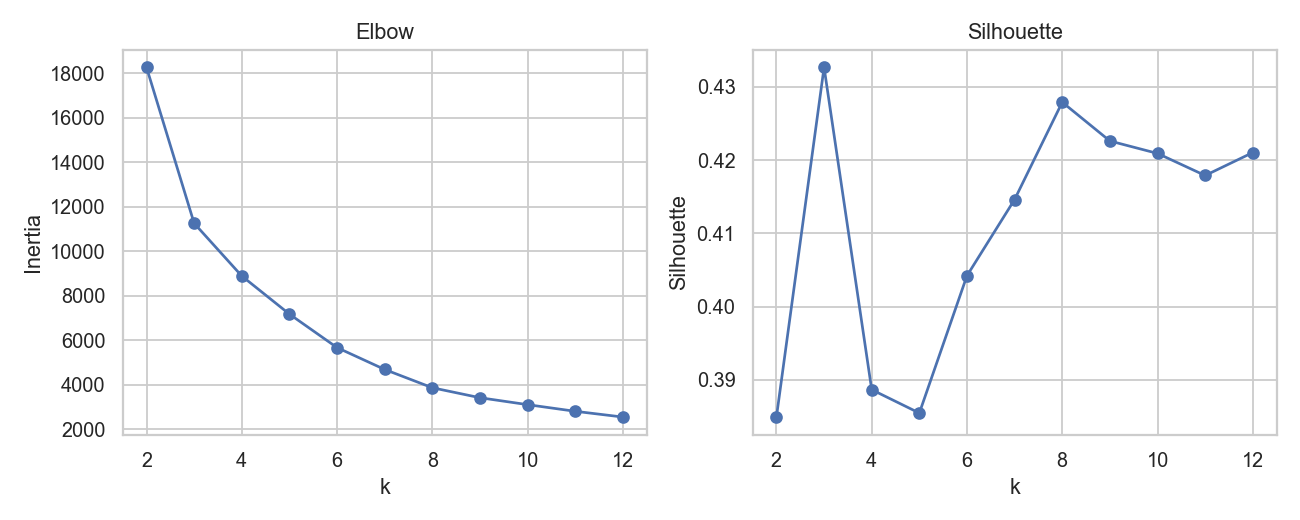

In [5]:
nums = json.load(open(ROOT / 'reports' / 'report_numbers.json', encoding='utf8'))
print('OLS cũ:', nums['old_ols'], '| mô hình tốt nhất:', nums['best_model'])
print('Kiểm định baseline OLS:', json.dumps(nums['baseline_diag'], indent=1))
print('K-Means k =', nums['kmeans']['k'])
display(Image(FIG / 'kmeans_elbow_silhouette.png'))

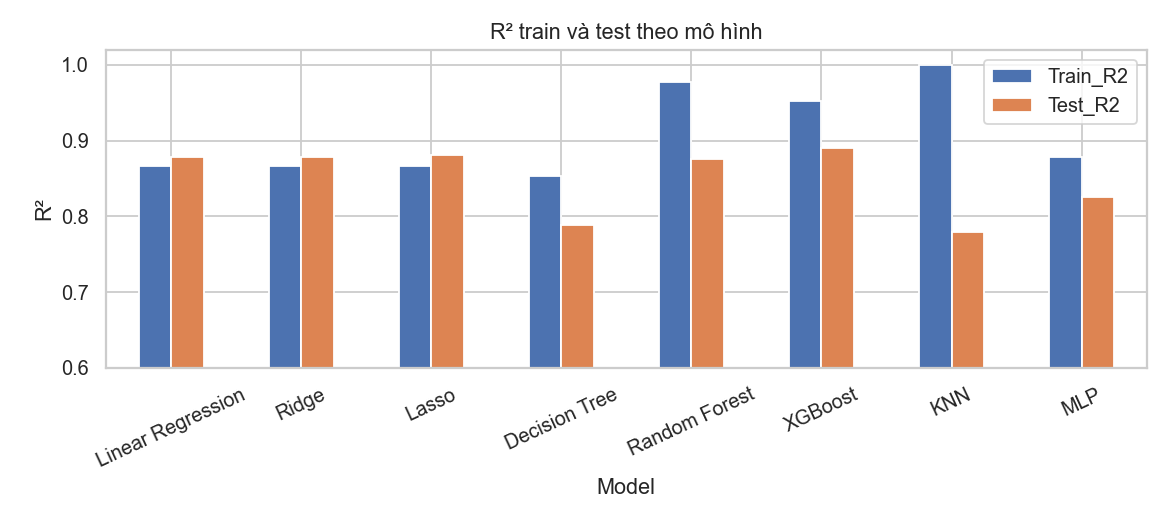

In [6]:
Image(FIG / 'model_comparison.png')

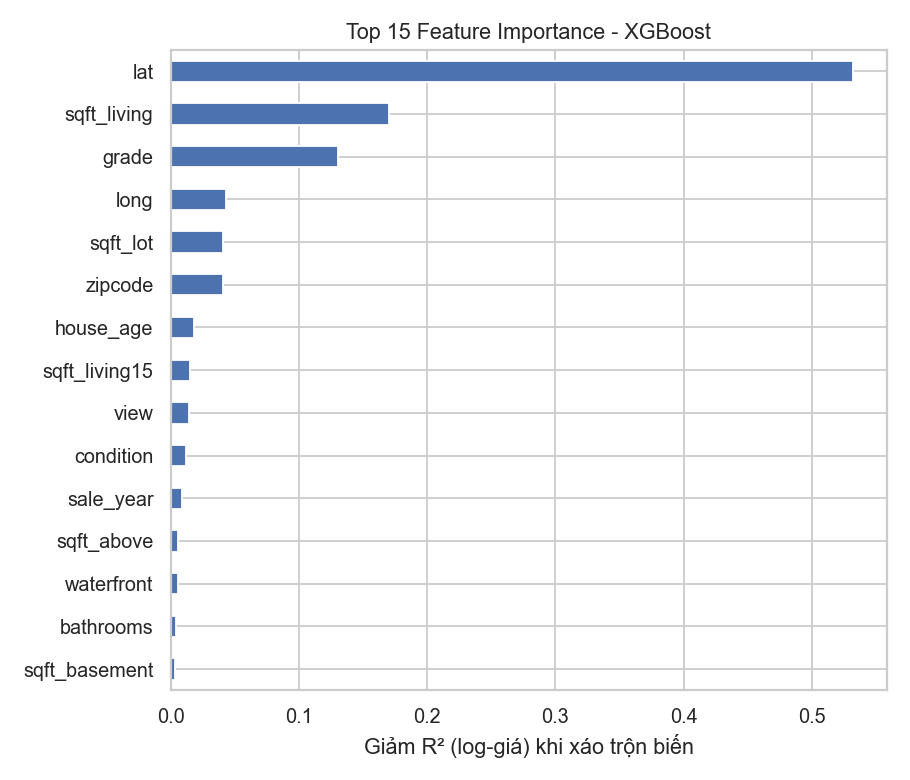

In [7]:
Image(FIG / 'feature_importance.png')

,n,MAE,MAPE,bias_pct
segment,,,,
10% đắt nhất,325,219291.97,14.25,-4.93
90% còn lại,2916,47223.66,11.25,1.64


Sai số < 10%: 58.7% | < 20%: 84.6%


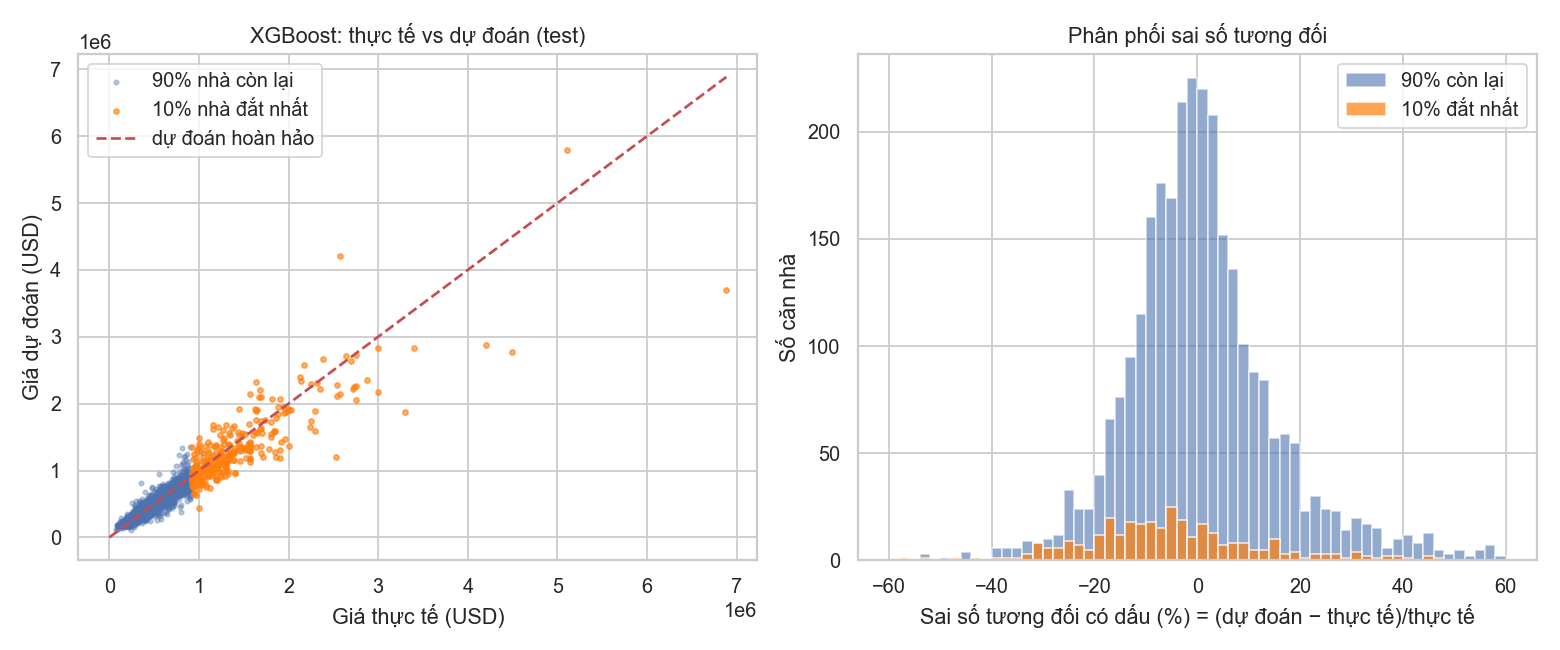

In [8]:
best = joblib.load(MODELS_DIR / 'best_model.joblib')
X_te, y_te = xy(test)
out = pd.DataFrame({'true': np.expm1(y_te), 'pred': np.expm1(best.predict(X_te))})
out['abs_err'] = (out['pred'] - out['true']).abs()
out['ape_%'] = out['abs_err'] / out['true'] * 100
out['signed_%'] = (out['pred'] - out['true']) / out['true'] * 100
out['segment'] = np.where(out['true'] >= out['true'].quantile(0.9), '10% đắt nhất', '90% còn lại')
display(out.groupby('segment').agg(n=('true', 'size'), MAE=('abs_err', 'mean'), MAPE=('ape_%', 'mean'), bias_pct=('signed_%', 'mean')).round(2))
print('Sai số < 10%:', f"{(out['ape_%'] < 10).mean():.1%}", '| < 20%:', f"{(out['ape_%'] < 20).mean():.1%}")
display(Image(FIG / 'best_model_predictions.png'))